In [146]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import importlib
import feature_utils
from sklearn.cluster import KMeans

importlib.reload(feature_utils)
from feature_utils import plot_rms_violin,find_active_periods,compare_waveforms

DATA_PATH = Path("centrifuge line datasets.parquet")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
pf = pq.ParquetFile(DATA_PATH)
display(pd.DataFrame({"column": pf.schema_arrow.names,
                      "parquet_type": [str(f.type) for f in pf.schema_arrow]}))
print(f"Rows: {pf.metadata.num_rows:,}; file size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
df = pq.read_table(DATA_PATH).to_pandas()


def calculate_raw_waveform_rms(value):
    if value is None or np.isscalar(value):
        return np.nan

    samples = np.asarray(value, dtype=float).ravel()
    if samples.size == 0 or not np.isfinite(samples).all():
        return np.nan

    return float(np.sqrt(np.mean(np.square(samples))))




,column,parquet_type
0,date,"timestamp[ns, tz=UTC]"
1,Motor DE_Z Short Wave High Frequency,list<element: double>
2,Motor DE_Z Long Wave High Frequency,list<element: double>
3,Motor DE_X Short Wave Low Frequency,list<element: double>
4,Motor DE_Y Short Wave Low Frequency,list<element: double>
5,Motor DE_Z Short Wave Low Frequency,list<element: double>
6,Motor DE_Temperature,list<element: double>
7,Motor DE_Z Short Wave Low Frequency RMS,double
8,Motor DE_X Short Wave Low Frequency RMS,double
9,Motor DE_Y Short Wave Low Frequency RMS,double


Rows: 26,502; file size: 499.8 MiB


# DataSet completeness

In [147]:
# Load the dataset
df = pf.read().to_pandas()

results = []

for col in df.columns:

    series = df[col]
    is_waveform = pa.types.is_list(
        pf.schema_arrow.field(col).type
    )

    missing = series.isna().sum()

    empty_arrays = 0
    arrays_with_nan = 0
    arrays_with_inf = 0
    min_length = None
    max_length = None

    if is_waveform:
        lengths = []

        for value in series.dropna():

            arr = np.asarray(value, dtype=float)

            lengths.append(len(arr))

            if len(arr) == 0:
                empty_arrays += 1

            if np.isnan(arr).any():
                arrays_with_nan += 1

            if np.isinf(arr).any():
                arrays_with_inf += 1

        if lengths:
            min_length = min(lengths)
            max_length = max(lengths)

    else:
        # Scalar numeric columns
        if pd.api.types.is_numeric_dtype(series):
            arrays_with_inf = np.isinf(
                series.dropna().to_numpy()
            ).sum()

    results.append({
        "Column": col,
        "Type": "Waveform" if is_waveform else "Scalar / Date",
        "Total Rows": len(series),
        "Missing": missing,
        "Missing %": round(missing / len(series) * 100, 2),
        "Empty Arrays": empty_arrays,
        "With NaN": arrays_with_nan,
        "With Inf": arrays_with_inf,
        "Min Samples": min_length,
        "Max Samples": max_length
    })

completeness_df = pd.DataFrame(results)

display(completeness_df)

,Column,Type,Total Rows,Missing,Missing %,Empty Arrays,With NaN,With Inf,Min Samples,Max Samples
0,date,Scalar / Date,26502,0,0.00,0,0,0,NaN,NaN
1,Motor DE_Z Short Wave High Frequency,Waveform,26502,23823,89.89,0,0,0,16384.0,16384.0
2,Motor DE_Z Long Wave High Frequency,Waveform,26502,25877,97.64,0,0,0,131072.0,131072.0
3,Motor DE_X Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,5120.0,5120.0
4,Motor DE_Y Short Wave Low Frequency,Waveform,26502,23824,89.90,0,0,0,5120.0,5120.0
5,Motor DE_Z Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,9216.0,9216.0
6,Motor DE_Temperature,Waveform,26502,23802,89.81,0,0,0,1.0,1.0
7,Motor DE_Z Short Wave Low Frequency RMS,Scalar / Date,26502,23146,87.34,0,0,0,NaN,NaN
8,Motor DE_X Short Wave Low Frequency RMS,Scalar / Date,26502,26367,99.49,0,0,0,NaN,NaN
9,Motor DE_Y Short Wave Low Frequency RMS,Scalar / Date,26502,26380,99.54,0,0,0,NaN,NaN


# Masking the Hold out data

In [148]:

RMS_COL = "Motor DE_Z Short Wave High Frequency RMS"

df["date"] = pd.to_datetime(df["date"], utc=True)

# Timestamp-based record types are a heuristic; validate against waveform presence.


final_test_mask = (
    (df["date"] >= "2025-04-29 00:00:00+00:00") &
    (df["date"] < "2025-06-10 00:00:00+00:00")
)

# Keep all records for waveform inspection and paired RMS comparisons.
df_dev = df.loc[~final_test_mask].copy()
df_hold_out = df.loc[final_test_mask].copy()


assert len(df) == len(df_dev) + len(df_hold_out)


# Ploting the Z short wave HF data


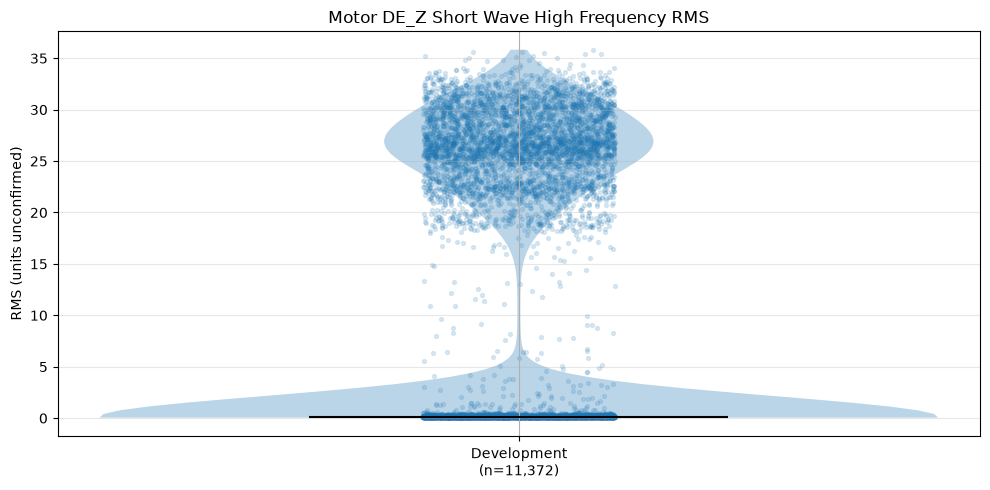

In [149]:
plot_rms_violin(
    [df_dev],
    column=RMS_COL,
    labels=["Development"],
)


Based on the olot we can see that therr are data for idle and running states

# Finding out the Cutoff RMS

In [150]:
def find_rms_cutoff(series):
    values = pd.to_numeric(series, errors="coerce").to_numpy(
        dtype=float, na_value=np.nan
    )
    values = values[np.isfinite(values)]

    if np.unique(values).size < 2:
        raise ValueError("Need at least two distinct RMS values.")

    model = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20,
    ).fit(values.reshape(-1, 1))

    centres = np.sort(model.cluster_centers_.ravel())
    cutoff = float(centres.mean())

    print(f"Low cluster centre:  {centres[0]:.4f}")
    print(f"High cluster centre: {centres[1]:.4f}")
    print(f"Cutoff:              {cutoff:.4f}")

    plt.figure(figsize=(10, 4))
    plt.hist(values, bins=60, edgecolor="white")
    plt.axvline(
        cutoff, color="red", linestyle="--",
        label=f"Cutoff = {cutoff:.4f}",
    )
    plt.xlabel("High-frequency Z RMS (units unconfirmed)")
    plt.ylabel("Number of readings")
    plt.title("Development summary-record RMS cutoff")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return cutoff

Low cluster centre:  0.1947
High cluster centre: 26.5382
Cutoff:              13.3665


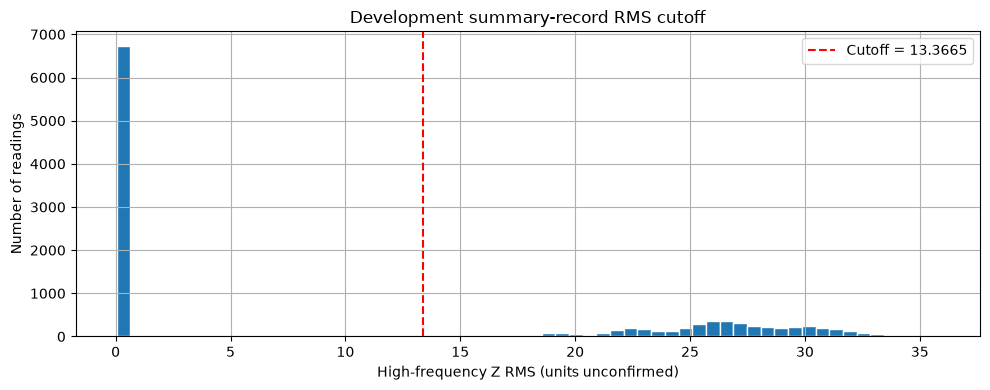

In [151]:
column = RMS_COL
cutoff = find_rms_cutoff(df_dev[column])


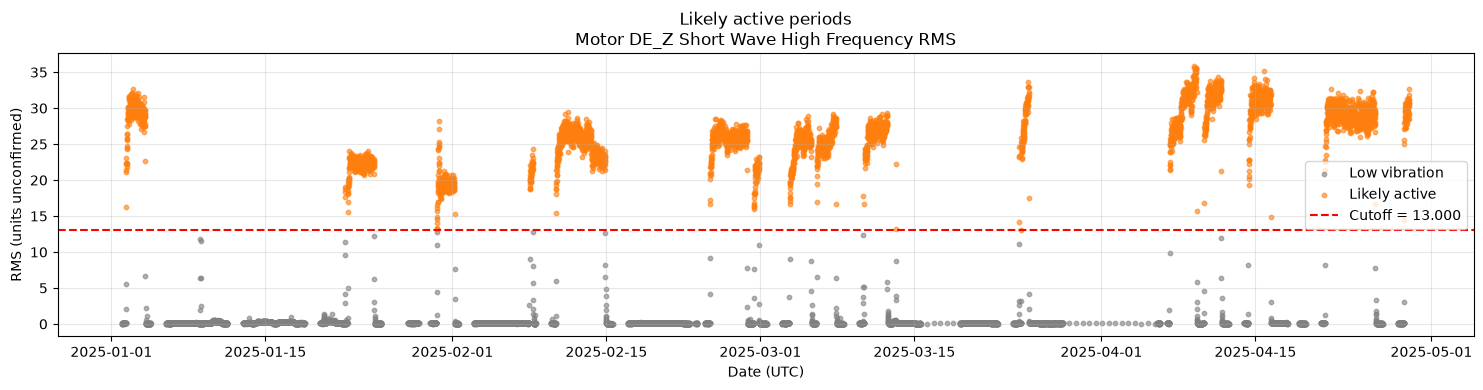

/Users/vinura/Work/Personal/Interviews/Groundupai/Vinura_Wanniarachchi_AIMLEngineer_Groundup/feature_utils.py:276: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(periods.round(3))


,first_active,last_active,readings,median_rms,observed_span_hours
run_id,,,,,
1,2025-01-02 08:11:21+00:00,2025-01-04 02:11:20+00:00,252,29.722,42.000
2,2025-01-22 05:51:20+00:00,2025-01-22 06:21:20+00:00,4,18.607,0.500
3,2025-01-22 11:51:20+00:00,2025-01-24 21:21:20+00:00,336,22.284,57.500
4,2025-01-30 13:59:58+00:00,2025-01-30 13:59:58+00:00,1,13.221,0.000
5,2025-01-30 14:21:20+00:00,2025-02-01 04:41:20+00:00,226,19.246,38.333
6,2025-02-08 00:31:20+00:00,2025-02-08 07:51:20+00:00,45,21.366,7.333
7,2025-02-10 09:51:20+00:00,2025-02-14 21:31:20+00:00,637,25.451,107.667
8,2025-02-24 09:59:58+00:00,2025-02-27 19:31:20+00:00,462,25.950,81.523
9,2025-02-28 09:51:20+00:00,2025-02-28 21:11:21+00:00,69,21.355,11.334


In [152]:
active_readings, active_periods = find_active_periods(
    df_dev,
    cutoff=13,
    rms_col=RMS_COL,
    max_gap="0.5h",
)

Based on the above data there are 21  runs in the machine , the first run is the desingated bearing fault which has a RMS of 29.722. Interstingly runs 16 - 21 have simialr RMS as well whil eht rest is of the runs are well belove . Which could Indicate that runs 16-21 may have some fault 

# Calculating RMS using waveforms

In [153]:
CALCULATED_SHF_RMS_COL = "Motor DE_Z Short Wave High Frequency RMS calculated"
CALCULATED_LHF_RMS_COL = "Motor DE_Z Long Wave High Frequency RMS calculated"
df_dev[CALCULATED_SHF_RMS_COL] = df_dev[
    "Motor DE_Z Short Wave High Frequency"
].map(calculate_raw_waveform_rms)

df_dev[CALCULATED_LHF_RMS_COL] = df_dev[
    "Motor DE_Z Long Wave High Frequency"
].map(calculate_raw_waveform_rms)

# Spliting data to three categories

In [154]:
# Use your specified period labels; these are not independently verified.
dates = pd.to_datetime(df_dev["date"], utc=True, errors="coerce")
rms = pd.to_numeric(df_dev[CALCULATED_SHF_RMS_COL], errors="coerce")
valid_rms = np.isfinite(rms) & (rms > 13)

periods = {
    "known_bearing_fault": (
        "2025-01-02 08:01:20+00:00",
        "2025-01-04 02:21:20+00:00",
    ),
    "healthy": (
        "2025-01-09 02:11:20+00:00",
        "2025-03-24 12:31:20+00:00",
    ),
    "suspicious": (
        "2025-03-24 16:31:20+00:00",
        "2025-04-28 23:51:20+00:00",
    ),
}

subsets = {}

for label, (start, end) in periods.items():
    mask = valid_rms & dates.between(
        pd.Timestamp(start),
        pd.Timestamp(end),
        inclusive="both",
    )
    subset = df_dev.loc[mask].copy()
    subset["date"] = dates.loc[mask]
    subsets[label] = subset.sort_values("date")

df_known_bearing_fault = subsets["known_bearing_fault"]
df_healthy = subsets["healthy"]
df_suspicious = subsets["suspicious"]

for label, subset in subsets.items():
    print(f"{label}: {len(subset):,} rows")

known_bearing_fault: 39 rows
healthy: 430 rows
suspicious: 276 rows


### Non-running readings: temperature box plot



Total temperature readings: 1,984
Unmatched temperatures: 118
Non-running temperature readings: 1,113
Valid temperature readings: 1,113


,Motor DE_Temperature
count,1113.000000
mean,37.455526
std,5.367439
min,28.000000
25%,35.000000
50%,37.000000
75%,38.000000
max,64.000000


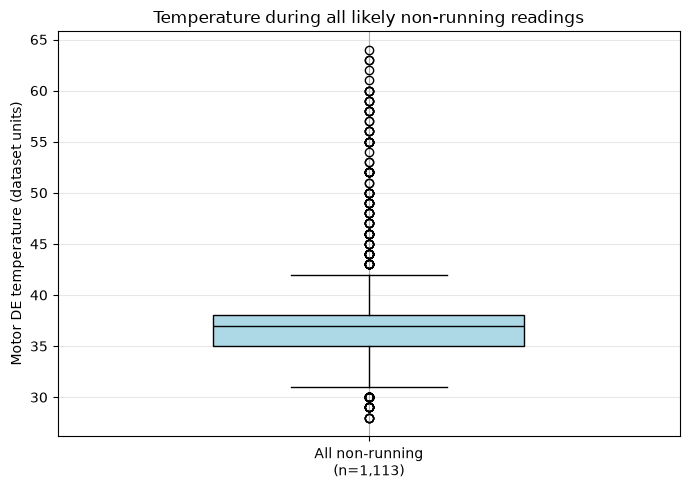

In [155]:
TEMPERATURE_COL = "Motor DE_Temperature"
NON_RUNNING_RMS_CUTOFF = 13  # Same threshold as find_active_periods above.

temperature_source = df_dev.copy()
temperature_source["date"] = pd.to_datetime(
    temperature_source["date"], utc=True, errors="coerce"
)
temperature_source = temperature_source.loc[temperature_source["date"].notna()].copy()

# Temperature is recorded separately, usually as a one-element list.
def scalar_temperature(value):
    if value is None:
        return np.nan
    values = np.asarray(value, dtype=float).ravel()
    return float(values[0]) if values.size == 1 and np.isfinite(values[0]) else np.nan

temperature_source["temperature_value"] = temperature_source[TEMPERATURE_COL].map(
    scalar_temperature
)
temperature_source["reported_rms"] = pd.to_numeric(
    temperature_source[RMS_COL], errors="coerce"
)
rms_records = temperature_source.loc[
    np.isfinite(temperature_source["reported_rms"]), ["date", "reported_rms"]
].rename(columns={"date": "rms_date"}).sort_values("rms_date")
temperature_records = temperature_source.loc[
    np.isfinite(temperature_source["temperature_value"]),
    ["date", "temperature_value"],
].sort_values("date")

temperature_matches = pd.merge_asof(
    temperature_records, rms_records,
    left_on="date", right_on="rms_date",
    direction="nearest", tolerance=pd.Timedelta("10min"),
)
temperature_matches["rms_time_offset"] = (
    temperature_matches["date"] - temperature_matches["rms_date"]
).abs()
df_non_running_temperature = temperature_matches.loc[
    temperature_matches["reported_rms"] < NON_RUNNING_RMS_CUTOFF
].copy()
temperatures = df_non_running_temperature["temperature_value"].to_numpy(dtype=float)
print(f"Total temperature readings: {len(temperature_records):,}")
print(f"Unmatched temperatures: {temperature_matches['reported_rms'].isna().sum():,}")
print(f"Non-running temperature readings: {len(df_non_running_temperature):,}")
print(f"Valid temperature readings: {temperatures.size:,}")
display(pd.Series(temperatures, name=TEMPERATURE_COL).describe().to_frame())

fig, ax = plt.subplots(figsize=(7, 5))
if temperatures.size == 0:
    ax.text(1, 0.5, "No valid temperature readings", ha="center",
            transform=ax.get_xaxis_transform())
else:
    ax.boxplot(
        temperatures, positions=[1], widths=0.5,
        patch_artist=True, showfliers=True,
        boxprops={"facecolor": "lightblue"},
        medianprops={"color": "black"},
    )

ax.set_xticks([1], [f"All non-running\n(n={temperatures.size:,})"])
ax.set_ylabel("Motor DE temperature (dataset units)")
ax.set_title("Temperature during all likely non-running readings")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Elevated temperature was observed during likely non-running periods, suggesting that an absolute temperature threshold alone may produce false alarms. Temperature’s usefulness for bearing-fault detection requires comparison between healthy and faulty periods under similar operating conditions.

# Analysing raw waveforms in running conditions

In [156]:
wave_cols = [
    "Motor DE_Z Short Wave High Frequency",
    "Motor DE_Z Long Wave High Frequency",
    "Motor DE_X Short Wave Low Frequency",
    "Motor DE_Y Short Wave Low Frequency",
    "Motor DE_Z Short Wave Low Frequency",
]

def has_valid_waveform(value):
    if value is None or np.isscalar(value):
        return False

    samples = np.asarray(value, dtype=float).ravel()
    return samples.size > 0 and np.isfinite(samples).all()

def get_complete_waveform_rows(df):
    mask = pd.Series(True, index=df.index)

    for col in wave_cols:
        mask &= df[col].map(has_valid_waveform)

    return df.loc[mask].copy()


df_fault_complete = get_complete_waveform_rows(df_known_bearing_fault)
df_healthy_complete = get_complete_waveform_rows(df_healthy)
df_suspicious_complete = get_complete_waveform_rows(df_suspicious)

for label, subset in [
    ("Bearing fault", df_fault_complete),
    ("Healthy", df_healthy_complete),
    ("Suspicious", df_suspicious_complete),
]:
    print(f"\n{label}: {len(subset):,} matching rows")
    print("Index labels:", subset.index.tolist())
    display(subset)


Bearing fault: 10 matching rows
Index labels: [104, 136, 168, 200, 232, 264, 295, 326, 358, 390]


,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal,Motor DE_Z Short Wave High Frequency RMS calculated,Motor DE_Z Long Wave High Frequency RMS calculated
104,2025-01-02 11:00:00+00:00,"[-38.59483169893065, -6.840671413934615, 29.24...","[-27.960602000063545, -50.44215220183719, -39....","[-4.693675409420393, 2.4067244535544887, 2.406...","[16.380690918256732, -2.0315487264197145, -2.0...","[13.20267808724505, 7.2570080338822045, 11.868...",[52.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.040945,29.846073
136,2025-01-02 15:00:00+00:00,"[16.02151633397989, 56.04361669318132, 28.4893...","[-5.885901338608278, 0.4221087180065979, 9.530...","[-11.917928145005135, -9.238808196707396, -9.2...","[-18.98853808667991, 7.38298140439656, 7.38298...","[1.3202753145839488, -7.1288347612474645, 0.54...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,30.717874,30.410959
168,2025-01-02 19:00:00+00:00,"[-12.684347895215069, -18.234737945030247, -33...","[25.141886351825292, 17.03864627909809, -12.01...","[-4.7099690809809545, 8.187870670113625, 8.187...","[-3.0015220983259496, 8.03215768874361, 8.0321...","[16.842991323042142, 2.6787911959173556, 4.902...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.298246,31.623779
200,2025-01-02 23:00:00+00:00,"[-5.206860266458534, -2.5881302429552306, -1.7...","[-84.04327349774883, -53.44201322310016, -9.41...","[-3.852272878782969, -13.519552692221623, -13....","[7.128341674935655, 3.1413817518769065, 3.1413...","[-16.51109115404769, -23.132031213471137, -8.2...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.029479,30.799221
232,2025-01-03 03:00:00+00:00,"[-25.295709684428402, -38.10936979943199, -16....","[14.4560670213001, -22.370853309224344, -46.26...","[4.346233713000402, 14.467353517680749, 14.467...","[-11.245242079861782, 14.43819742449341, 14.43...","[-22.353741499454674, 12.463838813035789, -2.8...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.447902,30.992320
264,2025-01-03 07:00:00+00:00,"[40.30903361678156, 46.369993671179145, 66.809...","[-22.669696882997187, -18.189856842790277, -9....","[29.059062204836664, -17.159416903228703, -17....","[-3.9609948923098273, -23.549314514290018, -23...","[10.524362262425711, 6.851552229461959, -1.597...",[54.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,30.971153,30.846805
295,2025-01-03 11:00:00+00:00,"[17.078260253376357, 5.401030148572318, -6.737...","[37.30622985463219, 55.11030001442509, 67.6110...","[26.919801777370594, 6.716602167256497, 6.7166...","[-40.09933189802905, 1.8881872916863358, 1.888...","[-8.588163270438802, 20.79431699327122, -12.52...",[54.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,32.006245,31.015894
326,2025-01-03 15:00:00+00:00,"[0.7840681088437123, 4.045128138111977, 10.567...","[28.520733295068794, 54.80685353098875, 39.901...","[8.673853848235012, -3.379745919151901, -3.379...","[-2.833602445316501, 4.169197419541888, 4.1691...","[-13.426486731831876, 2.0059034066750137, -6.7...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,28.660984,29.363234
358,2025-01-03 19:00:00+00:00,"[25.27240097511276, 20.611390933279836, 18.075...","[-21.123403218911562, -3.154633057640467, -0.8...","[3.600422946143226, -5.329976881515904, -5.329...","[-29.57941030416987, 7.684268976707244, 7.6842...","[-16.127972429906045, -1.4861422984944923, -7....",[52.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.591862,30.173408
390,2025-01-03 23:00:00+00:00,"[10.518158870646403, -13.67627134650047, -13.2...","[12.600276656820142, 9.56979662962135, 17.0142...","[-17.212


Healthy: 103 matching rows
Index labels: [3141, 3173, 3205, 3237, 3269, 3301, 3331, 3363, 3395, 3427, 3459, 3491, 4078, 4142, 4174, 4267, 4305, 4329, 4361, 5443, 5475, 5636, 5668, 5731, 5763, 5795, 5858, 5890, 5952, 6015, 6047, 6079, 6111, 6143, 6175, 6207, 6239, 6271, 6303, 6335, 6367, 6399, 6431, 7838, 7870, 7902, 7934, 7966, 7998, 8030, 8062, 8094, 8126, 8158, 8190, 8222, 8254, 8286, 8318, 8350, 8382, 8414, 8446, 8606, 8638, 8670, 8961, 8993, 9025, 9057, 9089, 9121, 9151, 9183, 9215, 9253, 9277, 9308, 9434, 9466, 9498, 9530, 9562, 9594, 9626, 9658, 9690, 9722, 9754, 10006, 10038, 10070, 10102, 10134, 10166, 10198, 10230, 10262, 10294, 10326, 10358, 10390, 11788]


,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal,Motor DE_Z Short Wave High Frequency RMS calculated,Motor DE_Z Long Wave High Frequency RMS calculated
3141,2025-01-22 11:00:00+00:00,"[-4.562369980522817, -16.618410088726705, -32....","[20.3061044671457, 32.31273457490613, 15.99096...","[12.343385980544554, -8.528373616667523, -8.52...","[7.4438908563461155, 2.827410945435986, 2.8274...","[-5.3148365223104435, 2.8707535511558575, -5.5...",[41.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,18.982167,18.537235
3173,2025-01-22 15:00:00+00:00,"[-2.3750053850853874, 27.369814881876664, 37.5...","[1.8334681814335454, 12.555438277664052, 34.55...","[-38.437343086352485, 43.956575323591096, 43.9...","[20.946134798901767, -19.48466442085555, -19.4...","[0.6010602885976866, 2.0833603019014433, -3.81...",[46.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,23.214595,22.676060
3205,2025-01-22 19:00:00+00:00,"[26.940452915132482, 34.48371298283382, 1.8237...","[8.302161515705166, -2.9303785851077464, 21.90...","[11.49389046568831, -41.49314851175586, -41.49...","[-25.338066089145286, 48.535372485228436, 48.5...","[-11.662064694511677, 2.0409754284741624, -19....",[50.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,22.942405,23.412581
3237,2025-01-22 23:00:00+00:00,"[-5.286870047450066, -15.135930135846138, -39....","[-30.684812427574457, 5.005677892750441, 15.18...","[-37.02449256674299, 15.791746413997316, 15.79...","[46.59558777266284, -14.51177104807357, -14.51...","[3.201711913501235, 3.7287519182314597, -1.129...",[51.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,24.396835,23.554289
3269,2025-01-23 03:00:00+00:00,"[-6.443535720673026, -3.874215697613181, -6.19...","[-17.3799964312401, -5.9827563289489945, 31.27...","[-40.89238907022445, -0.6031098477360501, -0.6...","[2.2599012688879156, 8.716141144293942, 8.7161...","[-5.196747907969339, 1.3912521511584686, -11.1...",[55.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,23.662714,23.376302
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10294,2025-03-11 23:00:00+00:00,"[-42.079683283552185, -37.83042324541475, -33....","[23.49543294120474, 6.514862788802816, -19.804...","[24.158635877531196, -43.43912281795201, -43.4...","[10.121161742179538, -14.610677780539845, -14....","[-1.4456481868029272, 4.170621863603529, 0.958...",[51.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,28.670245,28.553098
10326,2025-03-12 03:00:00+00:00,"[14.271089261995257, -20.908831053747235, 1.58...","[15.690331260054108, 7.5047411865878075, 6.401...","[6.682423105416092, 8.556343069252762, 8.55634...","[-1.2936956000339705, 17.06974404558423, 17.06...","[-5.190669948930413, 6.025400151734679, 3.3902...",[54.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.240801,28.619748
10358,2025-03-12 07:00:00+00:00,"[61.54220525510482, 8.689974780751982, -9.3940...","[11.347821054606356, -7.773849117012105, -2.98...","[-21.97976643520451, -13.303126602648263, -13....","[-18.561391313673084, -16.658191350401466, -16...","[-1.176125283993315, -1.4067052860627882, 1.54...",[56.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,27.879736,28.932296
10390,2025-03-12 11:00:00+00:00,"[-19.513785651211947, -9.730605563407153, -20....","[9.425687018418898, 11.385617036009421, -23.79...","[-8.957368499013683, 4.155191247937182, 4.1551...","[1.8345501833464368, -9.413849599579407, -9.41...","[-6.371422059137128, 1.4518280110771435, -7.78...",[54.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.611380,29.628214



Suspicious: 65 matching rows
Index labels: [11852, 11915, 11947, 12742, 12774, 12806, 12838, 12870, 12902, 12934, 12966, 12998, 13030, 13093, 13156, 13345, 13377, 13409, 13441, 13473, 13505, 13537, 13568, 13600, 13876, 13908, 13940, 13972, 14004, 14036, 14068, 14100, 14132, 14164, 14196, 14226, 14787, 14819, 14851, 14883, 14915, 14947, 14979, 15011, 15043, 15075, 15107, 15139, 15171, 15203, 15235, 15267, 15299, 15331, 15363, 15426, 15458, 15490, 15522, 15554, 15586, 15618, 15907, 15939, 15971]


,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal,Motor DE_Z Short Wave High Frequency RMS calculated,Motor DE_Z Long Wave High Frequency RMS calculated
11852,2025-03-24 19:00:00+00:00,"[-12.946638478013483, -14.725398493977991, 6.3...","[6.692063313311905, -21.965736943894058, -23.6...","[-14.775051808617718, 16.154387594498985, 16.1...","[-26.57292814343964, 6.479311218710791, 6.4793...","[-0.4691734026483658, -0.48564340279618534, -7...",[46.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,26.606280,25.911366
11915,2025-03-25 03:00:00+00:00,"[4.081716187146412, 15.973056293872105, 42.885...","[-28.22374440576084, 4.288035886034891, 43.420...","[7.08641942574468, 19.120499193508294, 19.1204...","[-1.3314240993058775, 16.30489556034445, 16.30...","[-1.9530693046383227, -3.171849315576967, 6.67...",[49.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.055948,31.061062
11947,2025-03-25 07:00:00+00:00,"[59.4073769846018, 43.49735684180814, 43.79381...","[66.89552691287724, 48.92675675160615, 12.1327...","[-6.527807170899905, 1.929232665894233, 1.9292...","[7.126023674980388, -9.514776003881707, -9.514...","[-1.9322190993730644, -1.8004590981905082, 14....",[50.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.674959,32.198947
12742,2025-04-07 07:00:00+00:00,"[1.5686589471843035, -38.71696141438224, -48.8...","[26.68611963236276, 40.40562975549642, 41.8220...","[-24.340357733399287, -1.3750781765884312, -1....","[-47.51416483306093, 4.345594166137744, 4.3455...","[-2.7795502104935537, -3.2571802147803197, -5....",[45.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,26.891354,27.085677
12774,2025-04-07 11:00:00+00:00,"[-17.41595356085054, -7.270433469793716, -10.7...","[70.68009022946728, 86.12895036812199, 74.7152...","[6.9368216942566505, 17.921701482267963, 17.92...","[-1.1011891349990037, 12.782410597072158, 12.7...","[2.428753146798247, -5.822716927259332, -0.486...",[47.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,26.756395,27.077813
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15586,2025-04-25 15:00:00+00:00,"[-2.887851273477281, -27.774021496832574, -48....","[51.259038424531354, 60.38341850642337, 64.072...","[-3.4035616530672996, 3.7505182088716538, 3.75...","[43.480368348406046, -24.049070348395617, -24....","[8.474690759654752, -26.7546395565312, -4.9648...",[56.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.286711,30.813280
15618,2025-04-25 19:00:00+00:00,"[-14.695541592464906, -8.05813153289364, -33.2...","[40.95318814954044, 15.86937792441131, -5.0639...","[-3.9585892048562528, 23.613410263053083, 23.6...","[0.6542621592489013, -5.440857723126101, -5.44...","[-12.794741774990044, 1.1388783500652693, -6.6...",[56.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.430913,29.333662
15907,2025-04-28 15:00:00+00:00,"[42.878532574169185, 20.13346237003043, 4.9810...","[8.51397841892765, 9.370418426614265, -10.8218...","[-16.481371416313777, 19.064547897713055, 19.0...","[9.527870988003997, -5.1316487290932855, -5.13...","[-1.903371579582906, -0.5198915671660664, -2.1...",[48.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.493533,29.083629
15939,2025-04-28 19:00:00+00:00,"[-26.307185229395145, -15.091115128730053, -13...","[29.999862501611915, 30.444552505603042, 13.03...","[-18.703755779675703, 8.975603686161776, 8.975...","[2.60646037157494, 38.313419682493986, 38.3134...","[3.7285857170580954, -8.574504393363085, 3.613...",[49.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,32.116015,31.364747


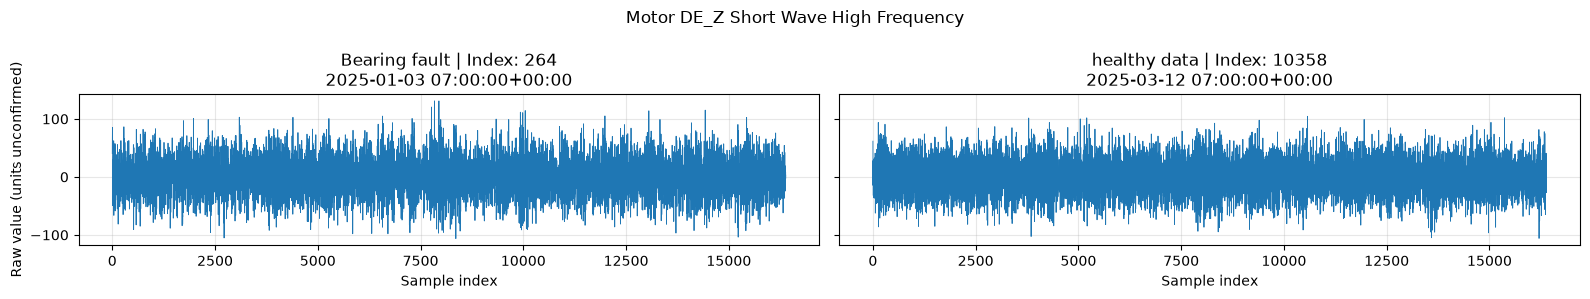

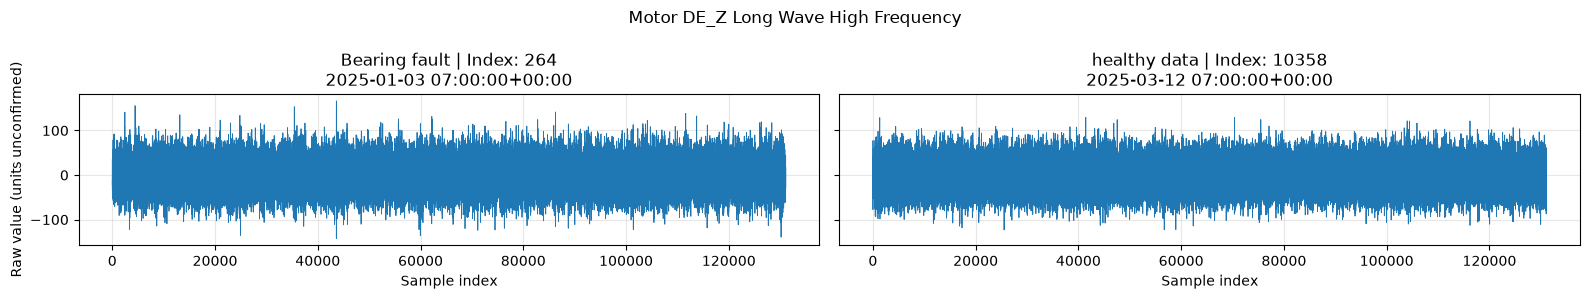

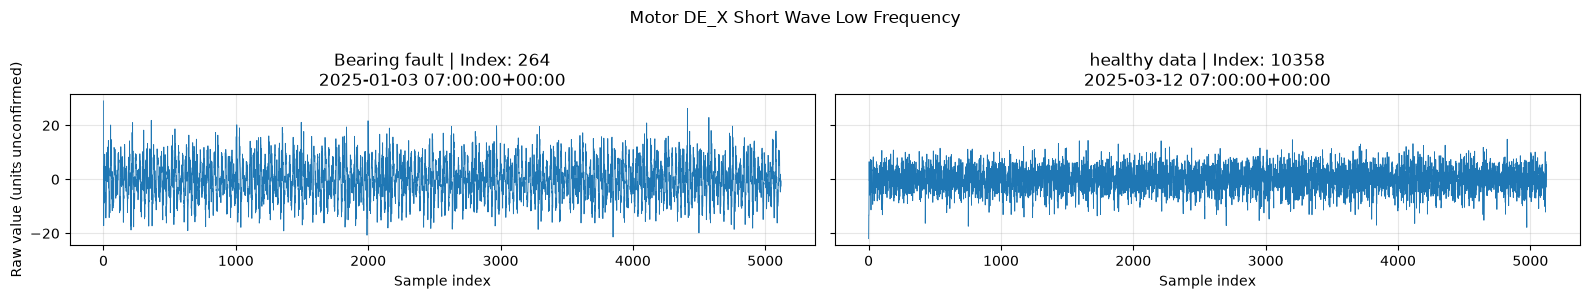

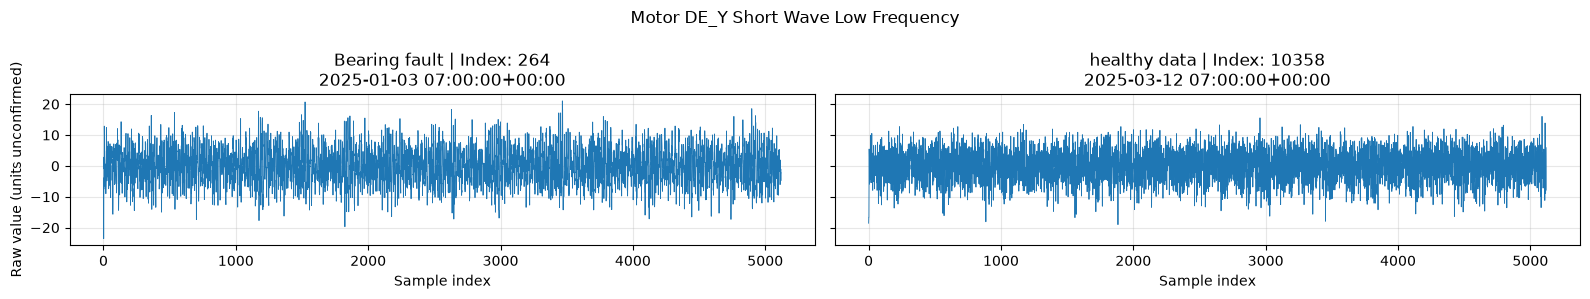

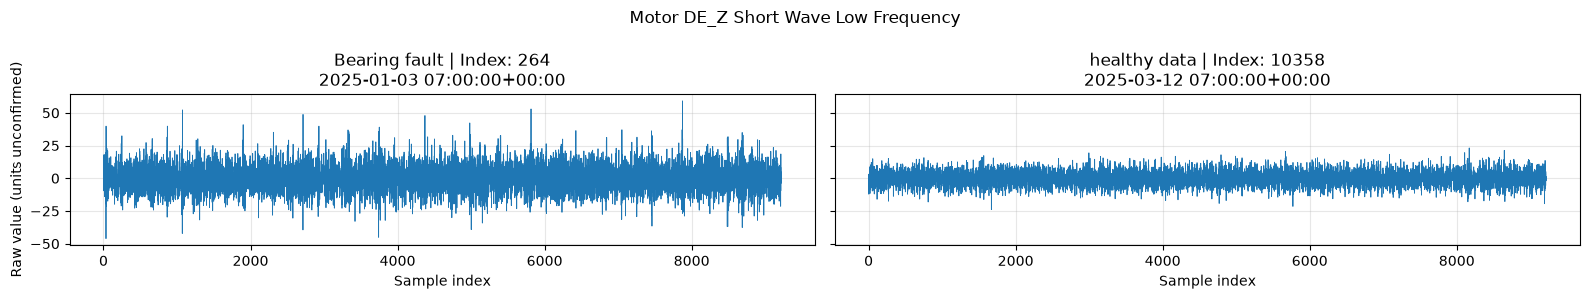

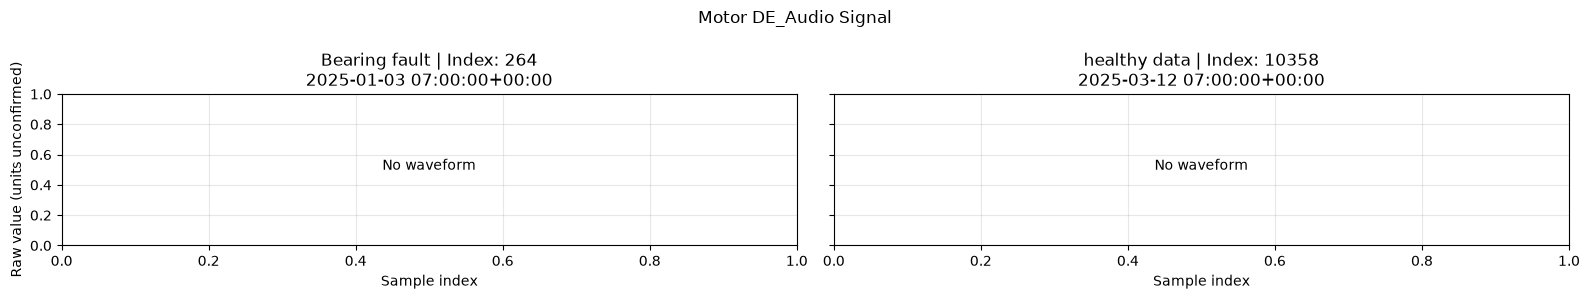

In [157]:
compare_waveforms(
    df_fault_complete, 264,
    df_healthy_complete, 10358,
    labels=("Bearing fault", "healthy data"),
)

The x short wave low frequency has a visible differnce yet it need to be verified using the FFT

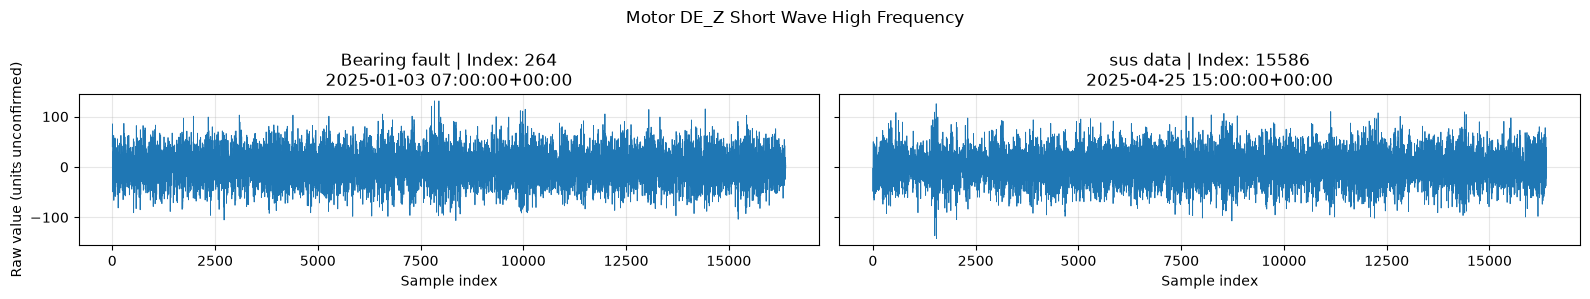

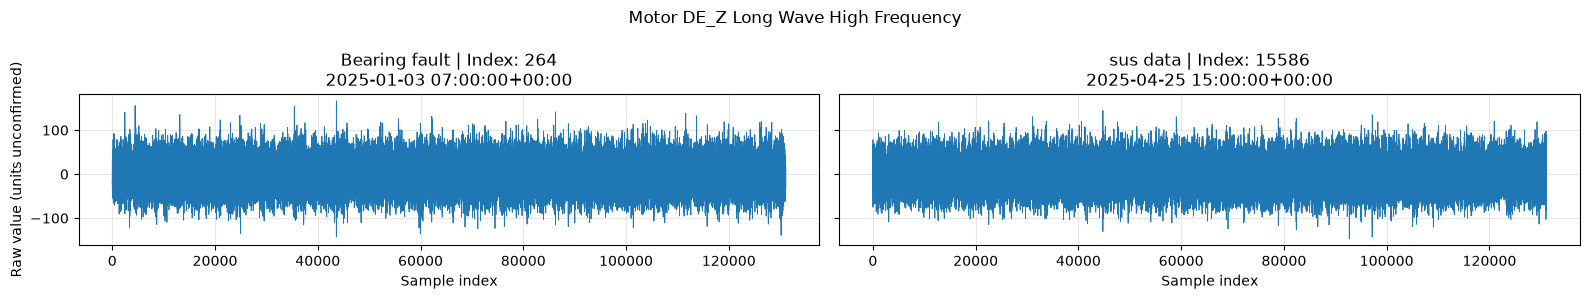

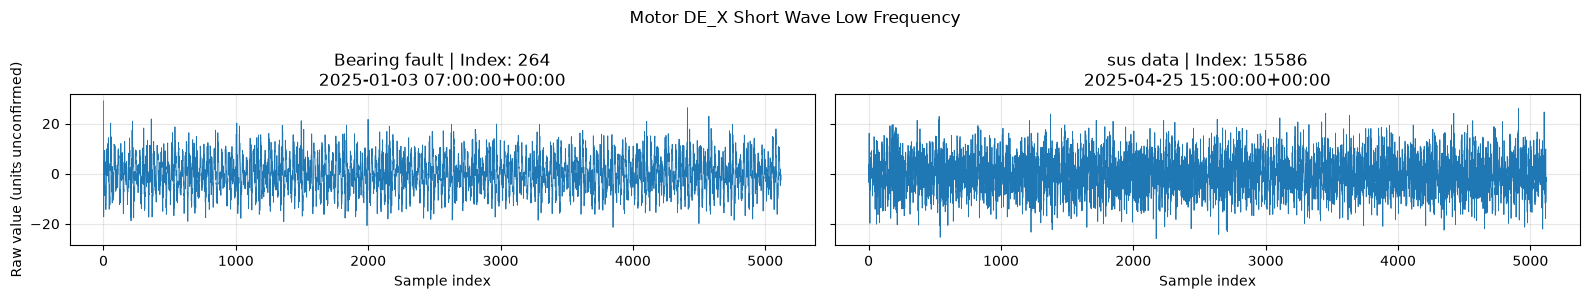

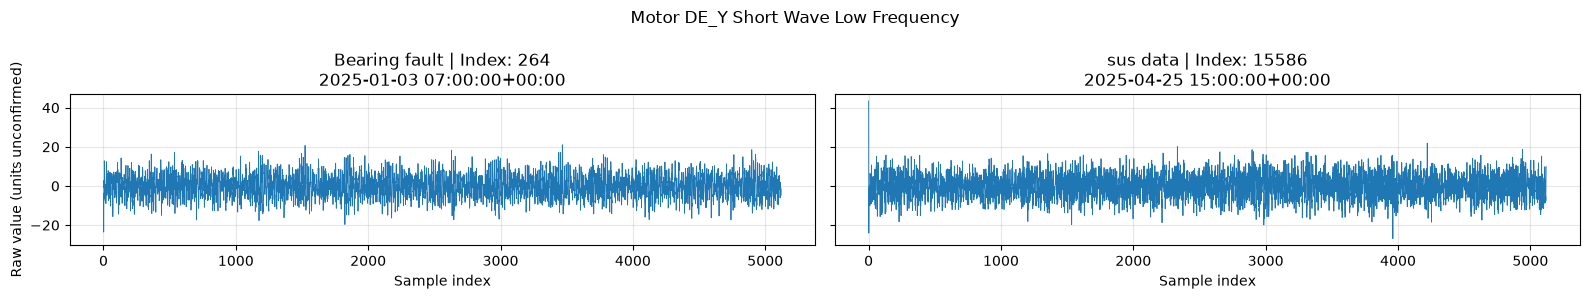

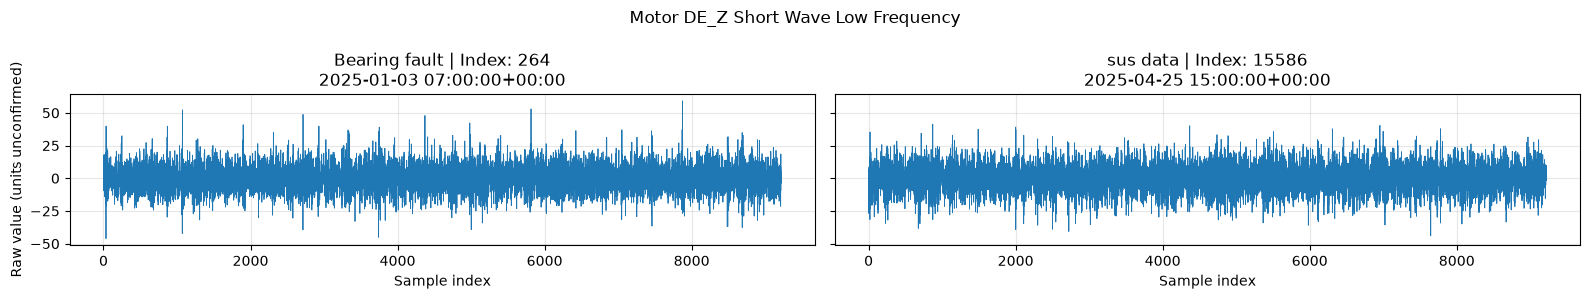

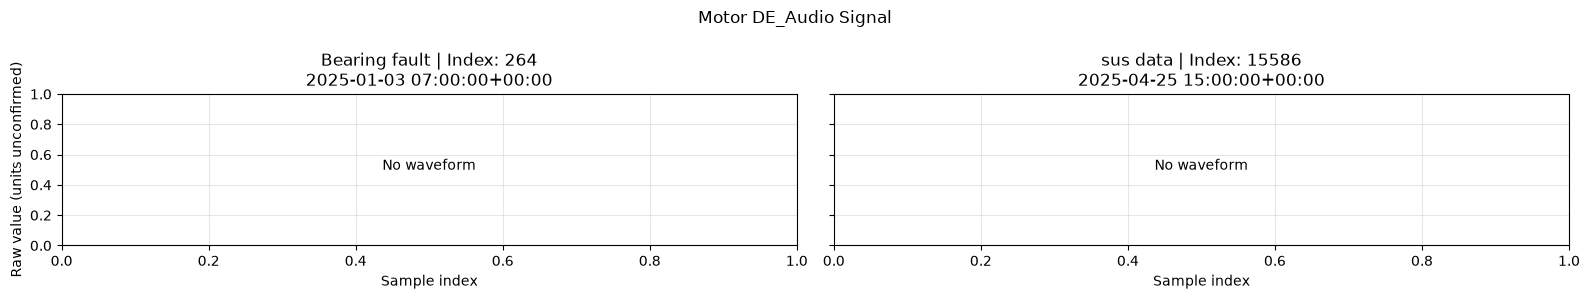

In [158]:
compare_waveforms(
    df_fault_complete, 264,
    df_suspicious_complete, 15586,
    labels=("Bearing fault", "sus data"),
)

# FFT feature extraction and analysis

In [159]:


WAVE_FS = {
    "Motor DE_Z Short Wave High Frequency": 51200,
    "Motor DE_Z Long Wave High Frequency": 51200,
    "Motor DE_Z Short Wave Low Frequency": 5120,
    "Motor DE_X Short Wave Low Frequency": 4001,
    "Motor DE_Y Short Wave Low Frequency": 4001,
    "Motor DE_Audio Signal": 11025,
}

def extract_signal_features(df, wave_fs):
    feature_dfs = {}

    columns = [
        "row_index",
        "date",
        "acceleration_rms",
        "acceleration_fft",
        "velocity_rms",
        "velocity_fft",
    ]

    for signal_col, sampling_rate in wave_fs.items():
        # Audio does not use acceleration/velocity processing.
        if signal_col == "Motor DE_Audio Signal":
            continue

        records = []

        for index, row in df.iterrows():
            value = row[signal_col]

            if value is None or np.isscalar(value):
                continue

            waveform = np.asarray(value, dtype=float).ravel()

            if waveform.size < 8 or not np.isfinite(waveform).all():
                continue

            features = feature_utils.get_features(waveform, sampling_rate)

            records.append({
                "row_index": index,
                "date": row["date"],
                **features,
            })

        feature_dfs[signal_col] = pd.DataFrame(
            records, columns=columns
        )

    return feature_dfs



features_fault = extract_signal_features(df_known_bearing_fault, WAVE_FS)
features_healthy = extract_signal_features(df_healthy, WAVE_FS)
features_suspicious = extract_signal_features(df_suspicious, WAVE_FS)


In [160]:
def compare_frequency_bands(
    groups,
    wave_fs,
    fft_col="acceleration_fft",
    bands=None,
    common_max_hz=None,
):
    """
    groups:
        {"Fault": features_fault, "Healthy": features_healthy, ...}

    Each features dictionary maps signal names to feature DataFrames.

    common_max_hz:
        Optional shared upper limit for comparing low- and high-frequency
        channels over the same frequency range.
    """
    if bands is None:
        bands = [
            (10, 100),
            (100, 500),
            (500, 1000),
            (1000, 1500),
            (1500, 2500),
            (2500, 5000),
            (5000, 10000),
            (10000, 20000),
        ]

    if any(low < 0 or high <= low for low, high in bands):
        raise ValueError("Each band must satisfy 0 <= low < high.")

    results = {}

    for signal_col, fs in wave_fs.items():
        recordings = []

        for group_name, feature_dict in groups.items():
            feature_df = feature_dict.get(signal_col)
            if feature_df is None or fft_col not in feature_df.columns:
                continue

            for _, row in feature_df.iterrows():
                spectrum = row[fft_col]
                if not isinstance(spectrum, (tuple, list)) or len(spectrum) != 2:
                    continue

                f = np.asarray(spectrum[0], dtype=float)
                a = np.asarray(spectrum[1], dtype=float)

                if (
                    f.ndim != 1 or a.shape != f.shape or f.size < 2
                    or not np.isfinite(f).all()
                    or not np.isfinite(a).all()
                    or not np.all(np.diff(f) > 0)
                ):
                    continue

                recordings.append((group_name, row, f, a))

        if not recordings:
            continue

        # Actual stored coverage also catches old/truncated FFT outputs.
        upper = min(fs / 2, *(f[-1] for _, _, f, _ in recordings))
        if common_max_hz is not None:
            upper = min(upper, common_max_hz)

        lower = max(f[0] for _, _, f, _ in recordings)
        usable_bands = [
            (low, high) for low, high in bands
            if low >= lower and high <= upper
        ]

        if not usable_bands:
            print(f"{signal_col}: no fully covered requested bands.")
            continue

        records = []

        for group_name, row, f, a in recordings:
            power = a ** 2

            # Fractions use the same requested analysis bands for all groups.
            masks = [(f >= low) & (f < high) for low, high in usable_bands]
            covered = np.logical_or.reduce(masks)
            total_power = power[covered].sum()

            for (low, high), mask in zip(usable_bands, masks):
                band_power = power[mask].sum() if mask.any() else np.nan

                records.append({
                    "group": group_name,
                    "row_index": row.get("row_index", row.name),
                    "date": row.get("date", pd.NaT),
                    "band": f"{low:g}–{high:g} Hz",
                    "band_rms": np.sqrt(band_power),
                    "power_fraction": (
                        band_power / total_power
                        if total_power > 0 else np.nan
                    ),
                })

        band_df = pd.DataFrame(records)
        results[signal_col] = band_df

        fig, axes = plt.subplots(1, 2, figsize=(16, 4))
        band_names = [f"{low:g}–{high:g} Hz" for low, high in usable_bands]

        for ax, metric, ylabel in zip(
            axes,
            ["band_rms", "power_fraction"],
            ["Band RMS (utils output units)", "Fraction of analysed band power"],
        ):
            medians = (
                band_df.groupby(["band", "group"])[metric]
                .median()
                .unstack("group")
                .reindex(band_names)
            )
            medians.plot.bar(ax=ax, width=0.8)
            ax.set_xlabel("Frequency band")
            ax.set_ylabel(ylabel)
            ax.set_title("Median across recordings")
            ax.tick_params(axis="x", rotation=45)
            ax.grid(axis="y", alpha=0.3)

        fig.suptitle(f"{signal_col} | {fft_col} | sampling rate: {fs:g} Hz")
        plt.tight_layout()
        plt.show()

    return results

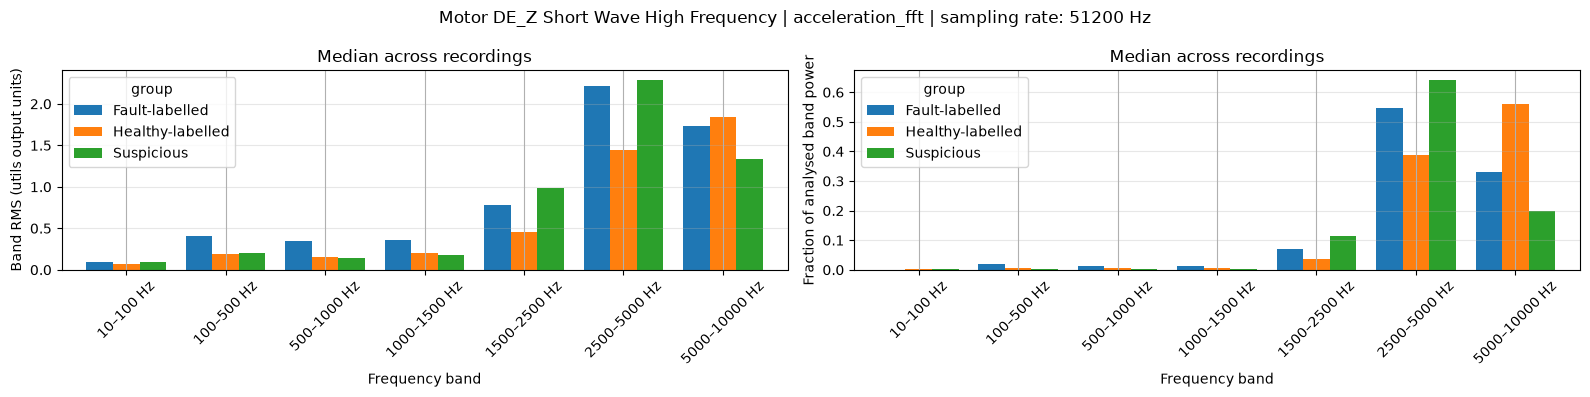

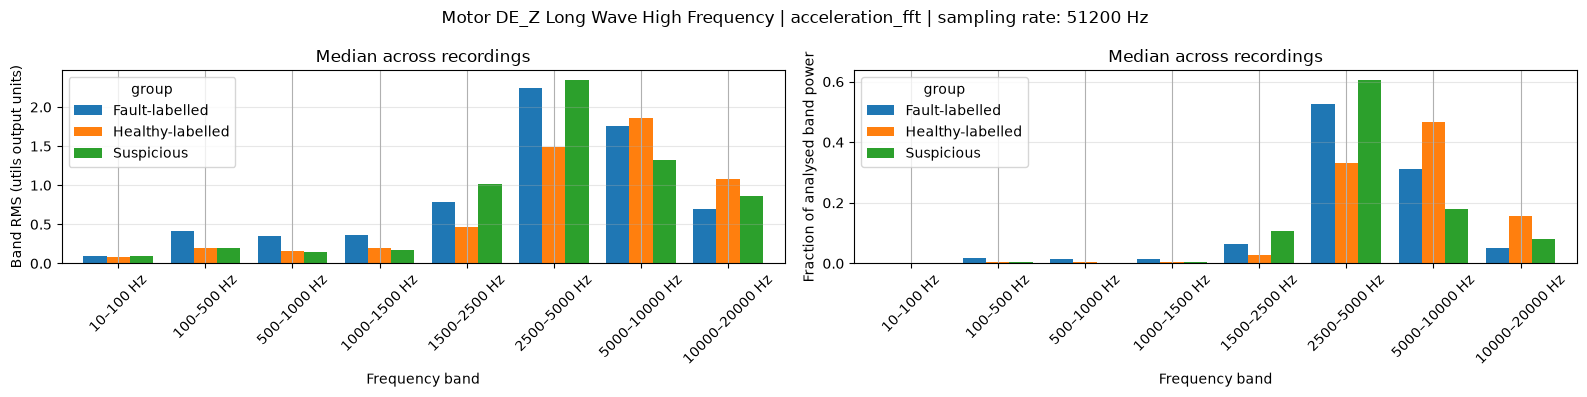

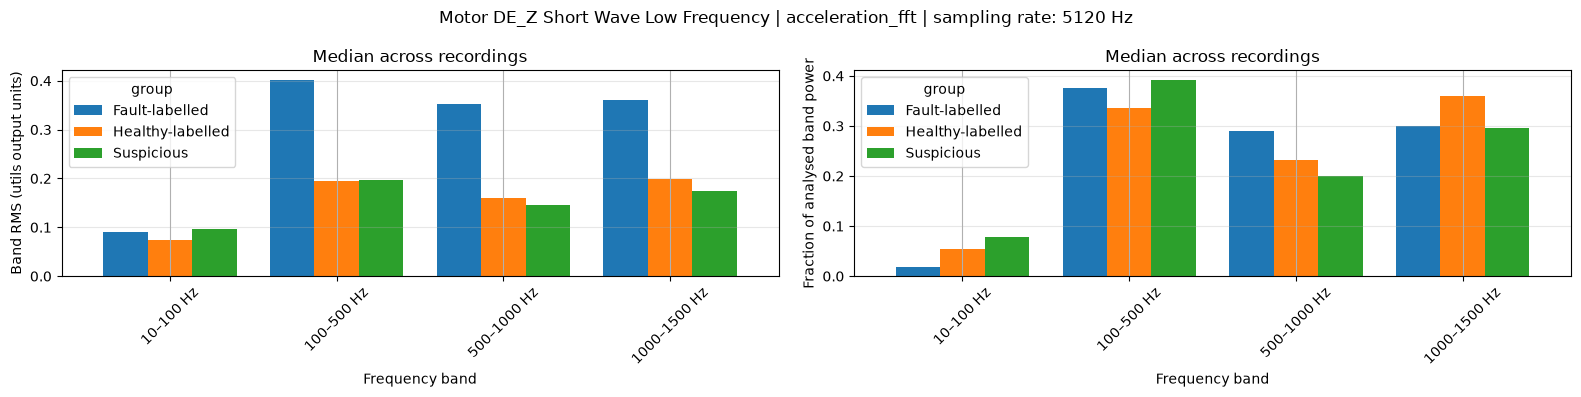

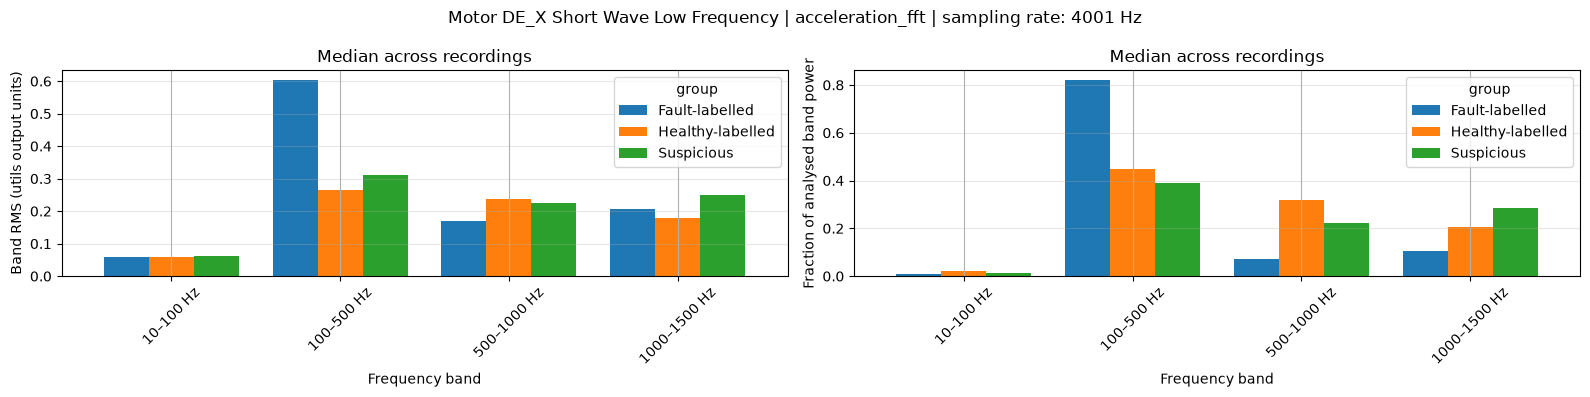

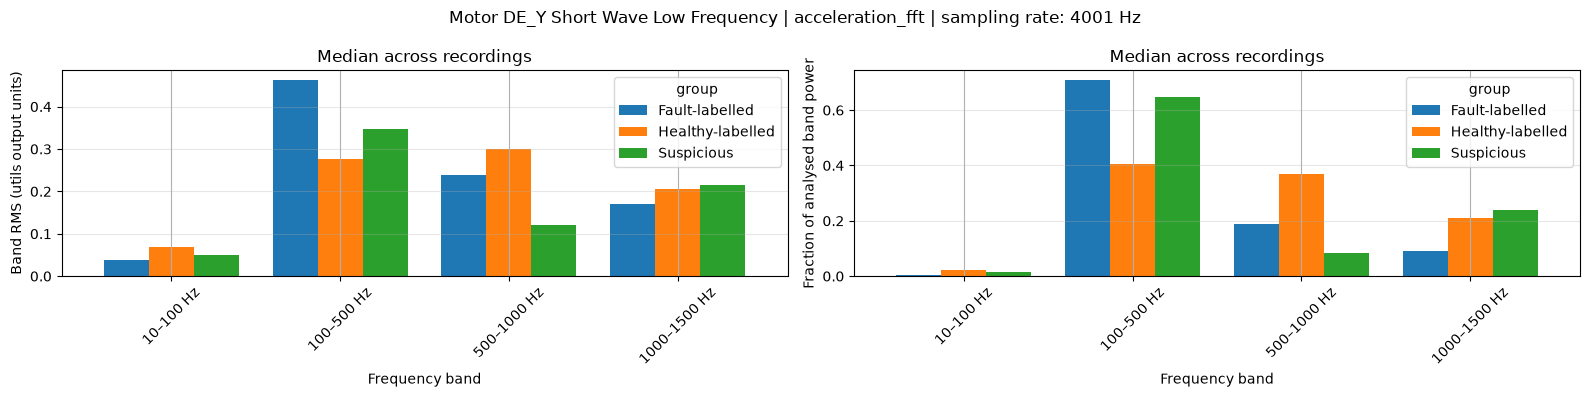

In [161]:
groups = {
    "Fault-labelled": features_fault,
    "Healthy-labelled": features_healthy,
    "Suspicious": features_suspicious,
}

band_results = compare_frequency_bands(
    groups,
    WAVE_FS,
    fft_col="acceleration_fft",
)

### Hypotheses about the labelled bearing fault period

The acceleration frequency-band comparisons suggest that the labelled bearing fault period differs from healthy operation in both vibration magnitude and the distribution of spectral power. These observations motivate the following hypotheses; they do not independently confirm a bearing fault mechanism.

#### Selected frequency bands

| Feature name | Signal | Spectrum | Selected band | Reference range |
|---|---|---|---|---|
| `x_acc_100_500` | Motor DE_X Short Wave Low Frequency | `acceleration_fft` | 100–500 Hz | 10–1500 Hz |
| `z_acc_2500_5000` | Motor DE_Z Short Wave High Frequency | `acceleration_fft` | 2500–5000 Hz | 10–10000 Hz |
| `y_acc_100_500` | Motor DE_Y Short Wave Low Frequency | `acceleration_fft` | 100–500 Hz | 10–1500 Hz |

For each band, band RMS describes vibration magnitude, while the power fraction describes the band's contribution to power within the reference range.

#### Hypothesis 1: The labelled fault period has a distinctive X-axis concentration at 100–500 Hz

The X-axis 100–500 Hz band has a median acceleration band RMS of approximately 0.60 during the fault-labelled period, compared with 0.27 during healthy operation. Its median power fraction is also substantially higher: approximately 82% versus 45%.

This suggests that the difference involves both increased vibration magnitude and a concentration of spectral power within this band. Therefore, `x_acc_100_500` is a candidate feature for distinguishing the labelled fault period from healthy operation.

The suspicious period does not reproduce the same high power fraction, suggesting that its vibration pattern may differ from the known-fault pattern.

#### Hypothesis 2: Increased Z-axis power at 2500–5000 Hz indicates a departure from healthy operation

The Z-axis short-wave 2500–5000 Hz band has a median band RMS of approximately 2.2–2.3 in the fault-labelled and suspicious periods, compared with approximately 1.45 in the healthy period. Both groups also show a higher power fraction than the healthy group.

A similar pattern appears in the Z-axis long-wave recordings, providing consistency across recording lengths. Therefore, `z_acc_2500_5000` is a candidate feature for identifying departures from the healthy baseline.

The suspicious period's resemblance to the fault-labelled period in this band motivates further investigation, but does not establish that both periods contain the same fault.

#### Hypothesis 3: Y-axis 100–500 Hz provides supporting evidence of a spectral shift

The Y-axis 100–500 Hz median band RMS increases from approximately 0.28 in the healthy period to 0.35 in the suspicious period and 0.46 in the fault-labelled period. Its median power fraction is approximately 40%, 65%, and 71%, respectively.

This suggests that the suspicious period shares some characteristics of the fault-labelled period on the Y axis. Therefore, `y_acc_100_500` is a supporting candidate feature. Its additional value should be assessed because X and Y features may contain overlapping information.

#### Interpretation and validation

Together, these bands suggest that the labelled fault period is associated with increased low-frequency acceleration on the X and Y axes and increased Z-axis acceleration within 2500–5000 Hz. The suspicious period shares some, but not all, of these characteristics.

These are empirical frequency bands selected from the development data. They should not be described as bearing characteristic frequencies without bearing geometry, rotational speed, and further spectral analysis.

The plots show group medians and do not establish separation between individual recordings. Validation should examine feature distributions and overlap, use splits by operating run or time, and assess whether the patterns persist under comparable operating conditions.

**Normalization note:** The displayed Z short-wave power fractions include the 10000–20000 Hz band in their denominator. The selected Z feature uses a 10–10000 Hz reference range, so its power fractions must be recalculated before reporting final feature values.

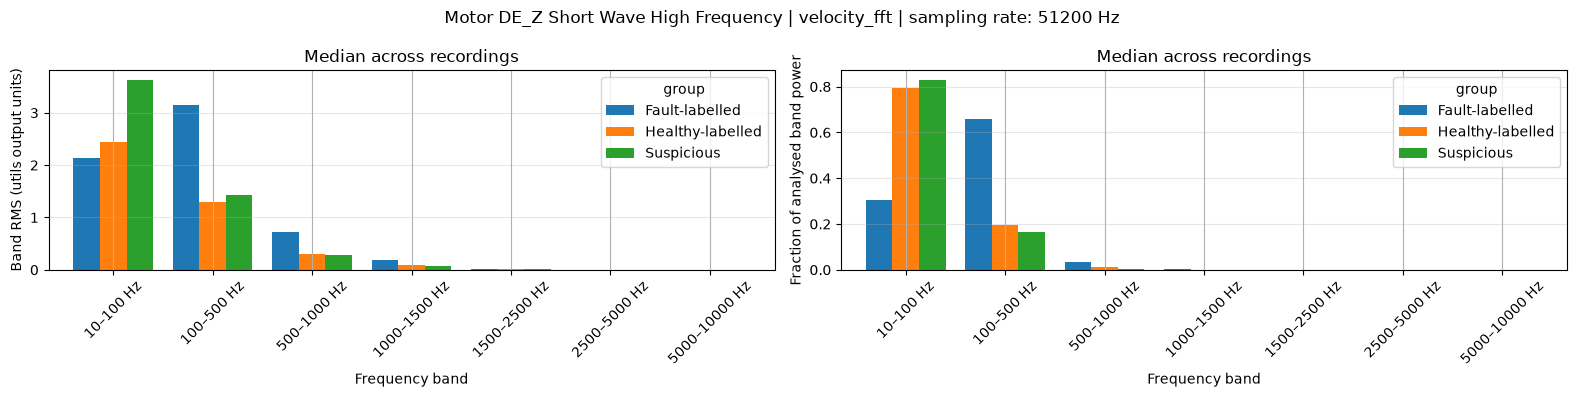

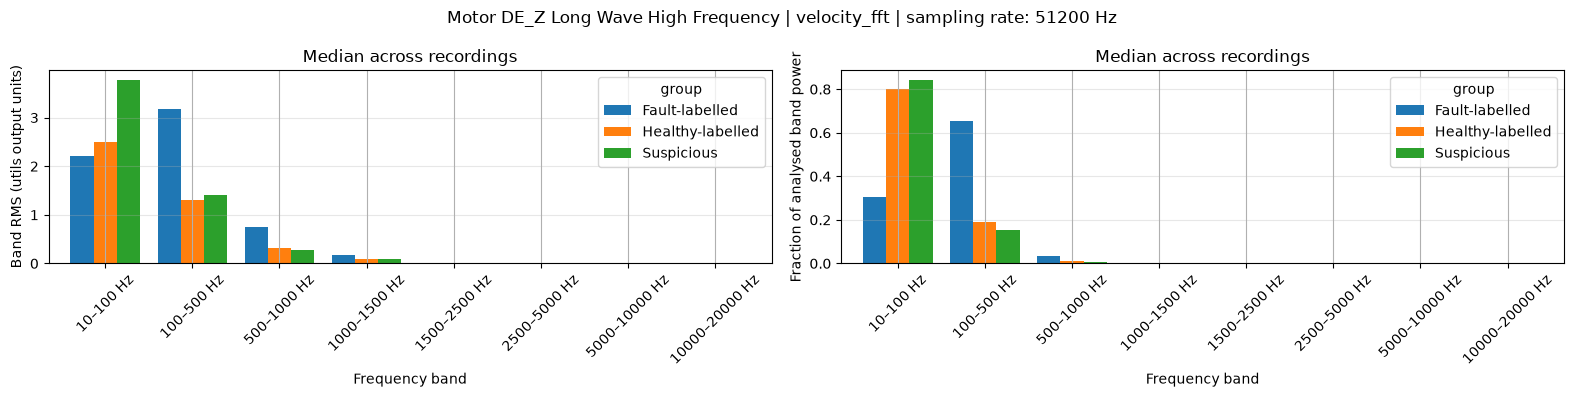

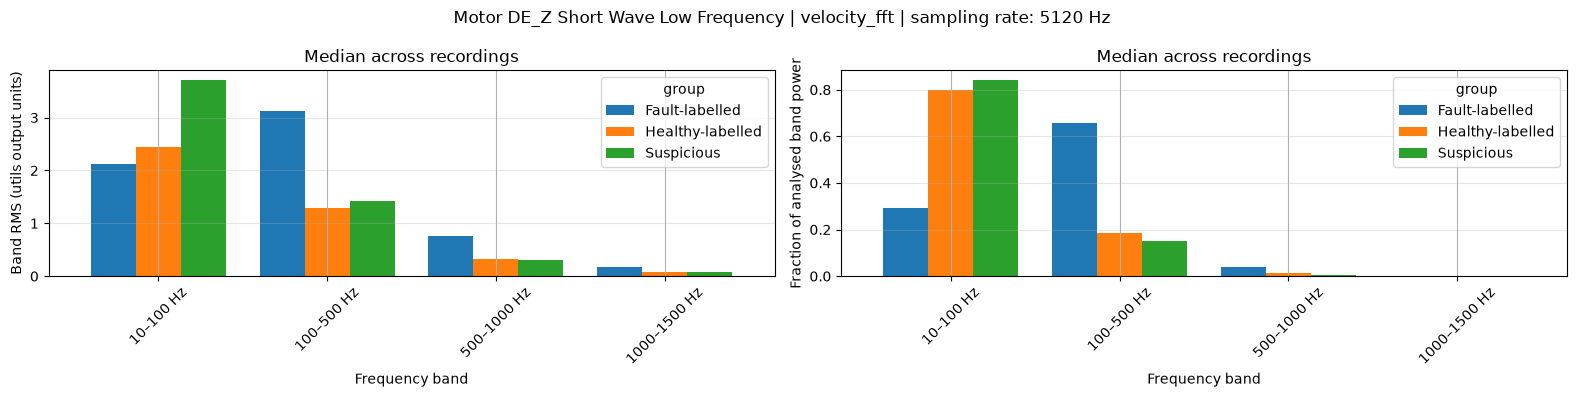

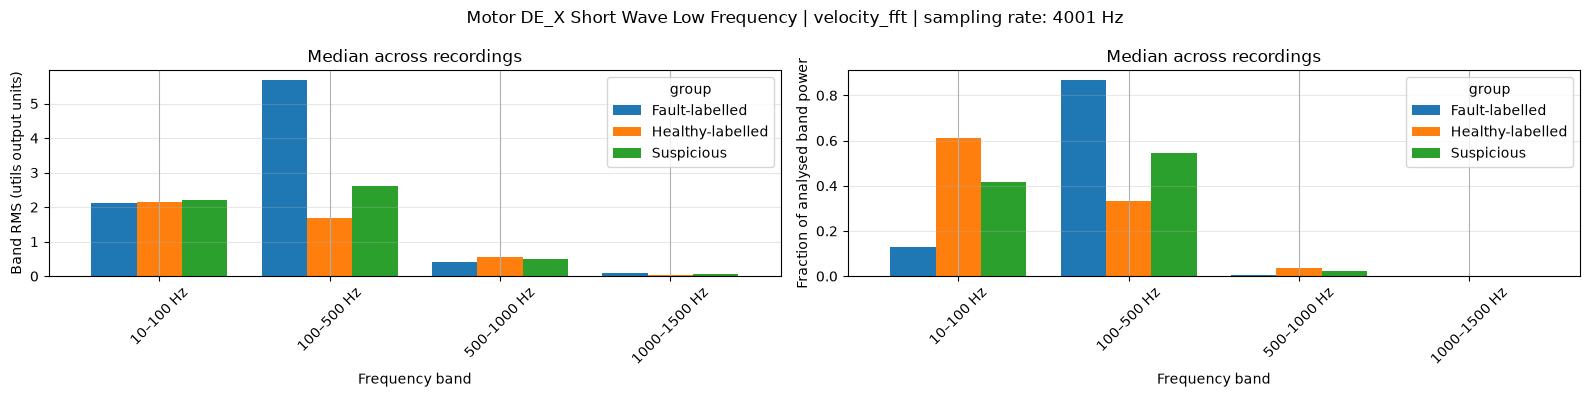

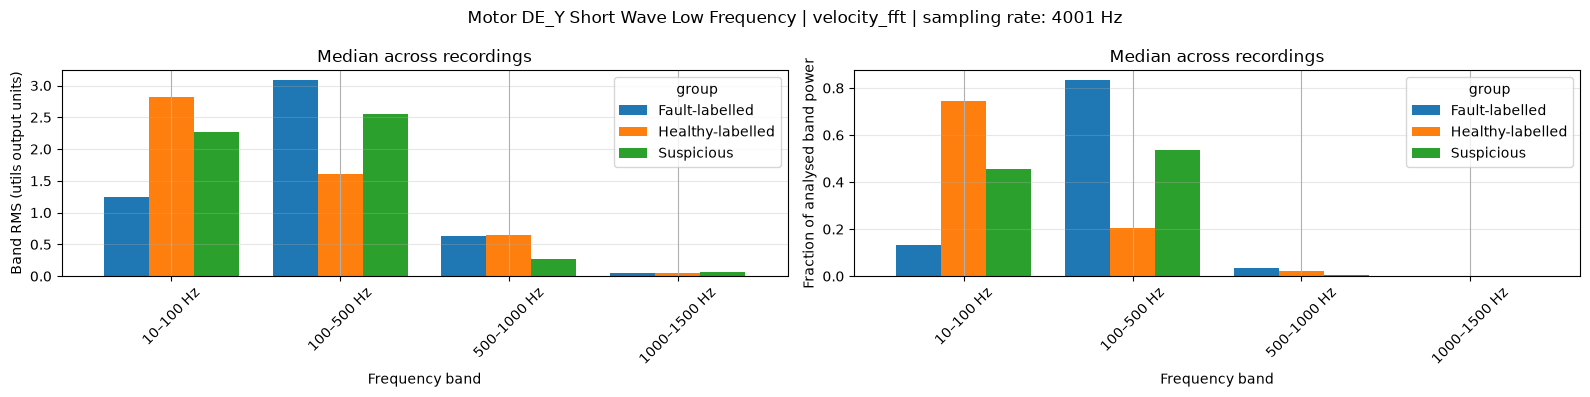

In [162]:
groups = {
    "Fault-labelled": features_fault,
    "Healthy-labelled": features_healthy,
    "Suspicious": features_suspicious,
}

band_results = compare_frequency_bands(
    groups,
    WAVE_FS,
    fft_col="velocity_fft",
)

### Hypotheses from the velocity spectra around the labelled bearing fault period

The velocity frequency-band comparisons suggest that the labelled bearing fault period is associated with increased vibration and greater spectral concentration within 100–500 Hz on both the X and Y axes. The following bands were selected as candidate features from the development data.

#### Selected frequency bands

| Feature name | Signal | Spectrum | Selected band | Reference range |
|---|---|---|---|---|
| `x_vel_100_500` | Motor DE_X Short Wave Low Frequency | `velocity_fft` | 100–500 Hz | 10–1500 Hz |
| `y_vel_100_500` | Motor DE_Y Short Wave Low Frequency | `velocity_fft` | 100–500 Hz | 10–1500 Hz |

Band RMS measures vibration magnitude within the selected band. Power fraction measures its contribution to the spectral power within the reference range. Numerical values below are approximate readings from the diagrams.

#### Hypothesis 1: X-axis velocity at 100–500 Hz distinguishes the labelled fault period from healthy operation

The X-axis 100–500 Hz median band RMS is approximately 5.7 during the fault-labelled period, compared with 1.7 during healthy operation and 2.6 during the suspicious period.

The corresponding median power fractions are approximately 87%, 33%, and 55%, respectively. Meanwhile, the 10–100 Hz median band RMS remains similar across the three groups.

This suggests that the fault-labelled difference is concentrated in 100–500 Hz rather than representing a uniform increase across all frequency bands. Therefore, `x_vel_100_500` is a strong candidate feature for distinguishing the labelled fault period from healthy operation.

The suspicious group's intermediate values motivate investigating whether some recordings share this fault-associated pattern. They do not establish progressive deterioration.

#### Hypothesis 2: Y-axis velocity shows a redistribution of spectral power toward 100–500 Hz

The Y-axis 100–500 Hz median band RMS is approximately 3.1 during the fault-labelled period, compared with 1.6 during healthy operation and 2.6 during the suspicious period.

Its median power fraction increases from approximately 20% in the healthy group to 54% in the suspicious group and 83% in the fault-labelled group. Conversely, the 10–100 Hz median band RMS is lower in the fault-labelled group than in the healthy group.

This suggests that the labelled fault period involves a change in spectral distribution, alongside increased vibration within the selected band. Therefore, `y_vel_100_500` is a complementary candidate feature, particularly when expressed as a power fraction.

The higher fraction may reflect both increased 100–500 Hz power and reduced power elsewhere; it should be interpreted together with band RMS.

#### Hypothesis 3: Agreement across axes strengthens the evidence for a distinct operating pattern

Both X and Y velocity spectra show increased 100–500 Hz band RMS and power fraction during the labelled fault period. The Z velocity plots also show greater concentration in this band during the fault-labelled period, providing additional consistency across channels.

This agreement supports the hypothesis that the labelled fault period contains a distinct vibration pattern. However, the additional predictive value of X and Y together must be assessed because their features may be correlated.

#### Interpretation and validation

These bands were selected because they show empirical differences between healthy and fault-labelled recordings. They should not be described as confirmed bearing characteristic frequencies without further evidence.

The suspicious group has intermediate X and Y velocity features, but this pattern alone cannot establish a bearing fault or its severity. Operating conditions and differences between recording periods remain alternative explanations.

The diagrams display medians, which can hide substantial overlap between individual recordings. Validation should examine feature distributions, assess performance using splits by operating run or time, and determine whether these velocity features add information beyond the selected acceleration features.

**Processing note:** The notebook derives velocity using a 10–1000 Hz bandpass filter. Although the selected reference range is 10–1500 Hz, power above 1000 Hz is attenuated by preprocessing. The resulting power fraction therefore describes the processed velocity spectrum within that reference range.